# Population data

CCT 2024 household survey demographic data downloaded from [the CCT Open Data Portal](https://odp-cctegis.opendata.arcgis.com/), specifically the [2024 Household Survey](https://odp-cctegis.opendata.arcgis.com/datasets/75ebd83593e24f1390cceb07ab234bb6_0/explore) (under Demography and Statistics)

In [1]:
import pandas as pd
# df = pd.read_csv("../data/2024_Household_Survey_-4393438653176099798.csv")

In [2]:
cols_with_dtype_issues = [
    "tenureother", "internetother", "water_drinkingother",
    "water_householdother", "water_outdoorother", "toiletother",
    "hhwasteother", "electricityother", "negeventother",
    "homebusinesstypeother", "noincome"
]

df_cct_households = pd.read_csv(
    "../data/2024_Household_Survey_-4393438653176099798.csv",
    dtype={col: "string" for col in cols_with_dtype_issues}
)

/tmp/ipykernel_334381/2267442284.py:8: DtypeWarning: Columns (0: column47, 1: exp_remittance) have mixed types. Specify dtype option on import or set low_memory=False.
  df_cct_households = pd.read_csv(


In [3]:
df_cct_households

,ObjectId,hhid,suburb,dwellingtype,language_int,consent,hhsize,hhchildren,material_walls,material_roof,...,exp_acc,exp_food,exp_education,exp_debt,exp_saving,exp_remittance,exp_none,date,hhwgt,ObjectId2
0,NaN,198331954,Bo-Kaap,Formal,English,Yes,4,0,Cement block/concrete,Asbestos,...,0,5000,0,0,0,0,No,02-25-24,18.712864,1.0
1,NaN,198332302,Bo-Kaap,Formal,English,Yes,2,0,Bricks,Wood,...,1000,1500,0,0,0,0,No,02-18-24,18.712864,2.0
2,NaN,198333074,De Waterkant/Green Point/Sea Point,Formal,English,Yes,3,1,Bricks,Tile,...,12000,6000,4000,0,0,0,No,02-24-24,256.391630,3.0
3,NaN,198333871,Bothasig,Formal,English,Yes,2,0,Bricks,Tile,...,0,3500,0,0,0,0,No,03-02-24,104.729090,4.0
4,NaN,198335080,Bothasig,Formal,English,Yes,3,1,Bricks,Tile,...,0,0,0,0,0,0,Yes,03-02-24,104.729090,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8313,NaN,208385099,Lakeside/Marina da Gama/Westlake,Formal,English,Yes,3,1,Bricks,Tile,...,6500,5000,2000,1500,2000,0,No,10-Sept-24,40.772549,8314.0
8314,NaN,209227926,Kommetjie/Scarborough,Formal,English,Yes,1,0,Bricks,Tile,...,0,8000,0,0,0,0,No,25-Sept-24,16.012644,8315.0
8315,NaN,209256781,Somerset West,Formal,English,Yes,5,0,Bricks,Tile,...,0,1000,0,0,0,0,No,26-Sept-24,380.062990,8316.0
8316,NaN,209257268,Somerset West,Formal,English,Yes,2,0,Bricks,Tile,...,0,8000,0,0,0,0,No,26-Sept-24,308.917390,8317.0


No geographic data so need to manually add it. Get the suburbs we need to locate:

In [4]:
suburbs = pd.unique(df_cct_households['suburb'])

In [5]:
for s in suburbs:
    print(s, end=", ")

Bo-Kaap, De Waterkant/Green Point/Sea Point, Bothasig, Delft, Hanover Park, Salt River/Woodstock, Silver Town, Parklands/Sunningdale, Joe Slovo Park, Athlone, Melkbosstrand, Camps Bay/Clifton, Endlovini/Enkanini, Kosovo, Montana/Montevideo, Freedom Park Airport, Belhar, Philippi East, Hazendal/Silvertown, Manenberg, Gugulethu, Phoenix, Bloubergstrand/Table View, Valhalla Park, Doornbach, Coniston Park/Sheraton Park, Bishop Lavis, Dunoon, Lavender Hill, Langa, Heathfield/Southfield, Retreat, Diep River/Plumstead, Grassy Park, Capricorn/Muizenberg, Browns Farms/Samora Machel, Bonteheuwel, Lansdowne, Crossroads/New Crossroads/Nyanga, Mowbray/Observatory, Philippi Small Holdings, Masiphumelele, Kensington, Elsies River, Heideveld, Imizamo Yethu, Steenberg, Bergvliet/Meadowridge, Brooklyn/Rugby, Milnerton, Bishopscourt/Constantia, Thornton, Dreyersdal, Zeekoei Vlei, Pelikan Park, Woodlands, Mxolisi Phetani (Site C), Makhaza, Makaya/Town 2, Ottery, Knole Park, Eyethu/Khaya, Wesbank, Fairways

Initially tried using google earth's gemini integration to get the boundaries of all the suburbs, but google earth does not allow exports.

Next i'll try using Overpass and OSM. 

For this it will be best to have exact names, so for the suburbs items with "/" combining nearby or overlapping suburbs, i'll separate them into individual items. The polygons can then be joined when getting to the geospatial work.

List of suburbs, comma-separated, with "/" removed: 
```
Schotschekloof, De Waterkant, Green Point, Sea Point, Bothasig, Delft, Hanover Park, Salt River, Woodstock, Silver Town, Parklands, Sunningdale, Joe Slovo Park, Athlone, Delft South, Winnie Madikizela - Delft, Delft Northeast, Melkbosstrand, Camps Bay, Clifton, Endlovini, Enkanini, Kosovo, Montana, Montevideo, Freedom Park Airport, Belhar, Philippi East, Hazendal, Silvertown, Manenberg, Gugulethu, Phoenix, Bloubergstrand, Table View, Valhalla Park, Doornbach, Coniston Park, Sheraton Park, Bishop Lavis, Dunoon, Lavender Hill, Langa, Heathfield, Southfield, Retreat, Diep River, Plumstead, Grassy Park, Capricorn, Muizenberg, Browns Farms, Samora Machel, Bonteheuwel, Lansdowne, Crossroads, New Crossroads, Nyanga, Mowbray, Observatory, Philippi Small Holdings, Masiphumelele, Kensington, Elsies River, Heideveld, Imizamo Yethu, Steenberg, Bergvliet, Meadowridge, Brooklyn, Rugby, Milnerton, Bishopscourt, Constantia, Thornton, Dreyersdal, Zeekoei Vlei, Pelikan Park, Woodlands, Site C, Makhaza, Makaya, Town 2, Ottery, Knole Park, Eyethu, Khaya, Wesbank, Fairways, Mfuleni, Maitland Garden Village, Ndabeni, Atlantis, Kalkfontein, Highbury, Sarepta, Parkwood, Summer Greens, Witsand, Lotus River, Nomzamo, Vrygrond, Rondebosch, Rosebank, Eersterivier, Scottsdene, Lentegeur, Claremont, Kenilworth, Edgemead, Kuyasa, Ndabeni Communal Trust, Blue Downs, Portland, Rocklands, Westridge, Harare, Strandfontein, Mandalay, Monte Vista, Wallacedene, Bellville South, Maitland, Parow, Bloekombos, Da Gama Park, nan, Zonnebloem, Ilitha Park, Wynberg, Blackheath, Bellville, Strand, Pella, Somerset West, Lwandle, Firgrove, Macassar, Goodwood, Vredehoek, Ruyterwacht, Kraaifontein, Fisantekraal, Kraaifontein East, Sir Lowry's Pass, Lakeside, Marina da Gama, Westlake, Newlands, Richwood, Kuils River, Hout Bay, Primrose Park, Surrey Estate, Oranjezicht, Klipheuwel, Site B: Victoria Mxenge, Tokai, Steenberg Estate, Mamre, Brackenfell, Tamboerskloof, Eastridge, Parow Valley, Fish Hoek, Philadelphia, Site B: Nonqubela, Eversdal, Kenridge, Welgemoed, Gardens, Kommetjie, Scarborough, Capri, Wolverivier, Plattekloof, Beacon Valley, Tafelsig, Somerset West Non Urban, Gordons Bay, Kuils River SH, Clovelly, Kalk Bay, St James, Durbanville, Noordhoek, Simons Town, Kirstenhof, Pinelands, Red Hill, Bellville Park, Morning Star AH, Panorama, Welgelegen, Ocean View, Langeberg, Cape Town Farms, Cape Town CBD, Glencairn, Llandudno, Firgrove Rural
```

Joined suburbs:
```
De Waterkant/Green Point/Sea Point, Salt River/Woodstock, Parklands/Sunningdale, Camps Bay/Clifton, Endlovini/Enkanini, Montana/Montevideo, Hazendal/Silvertown, Bloubergstrand/Table View, Coniston Park/Sheraton Park, Heathfield/Southfield, Diep River/Plumstead, Capricorn/Muizenberg, Browns Farms/Samora Machel, Crossroads/New Crossroads/Nyanga, Mowbray/Observatory, Bergvliet/Meadowridge, Brooklyn/Rugby, Bishopscourt/Constantia, Makaya/Town 2, Eyethu/Khaya, Maitland Garden Village/Ndabeni, Kalkfontein/Highbury/Sarepta, Rondebosch/Rosebank, Claremont/Kenilworth, Portland/Rocklands/Westridge, Lakeside/Marina da Gama/Westlake, Primrose Park/ Surrey Estate, Tokai/Steenberg Estate, Kenridge/Welgemoed, Kommetjie/Scarborough, Kalk Bay/St James, Panorama/Welgelegen
```

In QGIS with QuickOSM, got all the places tagged as 'suburb' in the area i'm considering. I got both polygons and points - polygons are more useful, but there are some gaps where there are no polygons, and where there is a point but no polygon i'm thinking i could manually create some polygons (not of the exact area, so not something i could add to OSM, but close enough for the purposes of this analyisis. I can also use google maps to see what the border should be)

Made a CSV with one column ("name") and records for each suburb.

First i want to know how many of my suburbs from the survey data are missing from the OSM data. There may be some that have slightly different names which can be resolved, and there are some where i may need to add the spatial data. I'll copy and clean the names from OSM into a list, and create a list from my separated suburbs above. 

Although the suburbs from the survey were cleaned up by separating combined suburbs, there are some cases in OSM where names have aliases in parentheses, so we'll search for the tidied names in the names from OSM.

In [6]:
def normalize_place_names(names: list[str]) -> list[str]:
    # return [" ".join(name.casefold().split()) for name in names]
    return [" ".join(name.split()) for name in names]

suburb_names_survey = normalize_place_names(["Schotschekloof", "De Waterkant", "Green Point", "Sea Point", "Bothasig", "Delft", "Hanover Park", "Salt River", "Woodstock", "Silver Town", "Parklands", "Sunningdale", "Joe Slovo Park", "Athlone", "Delft South", "Winnie Madikizela - Delft", "Delft Northeast", "Melkbosstrand", "Camps Bay", "Clifton", "Endlovini", "Enkanini", "Kosovo", "Montana", "Montevideo", "Freedom Park Airport", "Belhar", "Philippi East", "Hazendal", "Silvertown", "Manenberg", "Gugulethu", "Phoenix", "Bloubergstrand", "Table View", "Valhalla Park", "Doornbach", "Coniston Park", "Sheraton Park", "Bishop Lavis", "Dunoon", "Lavender Hill", "Langa", "Heathfield", "Southfield", "Retreat", "Diep River", "Plumstead", "Grassy Park", "Capricorn", "Muizenberg", "Browns Farms", "Samora Machel", "Bonteheuwel", "Lansdowne", "Crossroads", "New Crossroads", "Nyanga", "Mowbray", "Observatory", "Philippi Small Holdings", "Masiphumelele", "Kensington", "Elsies River", "Heideveld", "Imizamo Yethu", "Steenberg", "Bergvliet", "Meadowridge", "Brooklyn", "Rugby", "Milnerton", "Bishopscourt", "Constantia", "Thornton", "Dreyersdal", "Zeekoei Vlei", "Pelikan Park", "Woodlands", "Site C", "Makhaza", "Makaya", "Town 2", "Ottery", "Knole Park", "Eyethu", "Khaya", "Wesbank", "Fairways", "Mfuleni", "Maitland Garden Village", "Ndabeni", "Atlantis", "Kalkfontein", "Highbury", "Sarepta", "Parkwood", "Summer Greens", "Witsand", "Lotus River", "Nomzamo", "Vrygrond", "Rondebosch", "Rosebank", "Eersterivier", "Scottsdene", "Lentegeur", "Claremont", "Kenilworth", "Edgemead", "Kuyasa", "Ndabeni Communal Trust", "Blue Downs", "Portland", "Rocklands", "Westridge", "Harare", "Strandfontein", "Mandalay", "Monte Vista", "Wallacedene", "Bellville South", "Maitland", "Parow", "Bloekombos", "Da Gama Park", "nan", "Zonnebloem", "Ilitha Park", "Wynberg", "Blackheath", "Bellville", "Strand", "Pella", "Somerset West", "Lwandle", "Firgrove", "Macassar", "Goodwood", "Vredehoek", "Ruyterwacht", "Kraaifontein", "Fisantekraal", "Kraaifontein East", "Sir Lowry's Pass", "Lakeside", "Marina da Gama", "Westlake", "Newlands", "Richwood", "Kuils River", "Hout Bay", "Primrose Park", "Surrey Estate", "Oranjezicht", "Klipheuwel", "Site B: Victoria Mxenge", "Tokai", "Steenberg Estate", "Mamre", "Brackenfell", "Tamboerskloof", "Eastridge", "Parow Valley", "Fish Hoek", "Philadelphia", "Site B: Nonqubela", "Eversdal", "Kenridge", "Welgemoed", "Gardens", "Kommetjie", "Scarborough", "Capri", "Wolverivier", "Plattekloof", "Beacon Valley", "Tafelsig", "Somerset West Non Urban", "Gordons Bay", "Kuils River SH", "Clovelly", "Kalk Bay", "St James", "Durbanville", "Noordhoek", "Simons Town", "Kirstenhof", "Pinelands", "Red Hill", "Bellville Park", "Morning Star AH", "Panorama", "Welgelegen", "Ocean View", "Langeberg", "Cape Town Farms", "Cape Town CBD", "Glencairn", "Llandudno", "Firgrove Rural"])
suburb_names_osm_polygons = normalize_place_names(["Zeekoevlei", "Wynberg", "WP Park", "Woodstock", "Woodside Village", "Wingfield", "Windmill Beach", "Windermere", "Wildwood Island", "Whale Rock", "Wetton", "Westoe", "Weltevreden Hills", "Welgemoed", "Welgelegen", "Welcome", "Water-Vliet", "Warehouse Area", "Walmer Estate", "Vrygrond", "Vredelust", "Vredehoek", "Vierlanden Kleinhoewes", "Vierlanden", "Victor Verster", "Vermont", "Vasco Estate", "Vanguard", "Van Riebeeckshof", "Val De Vie", "V&A Waterfront", "University Estate", "Tygerdal", "Tyger Valley", "Townsend Estate", "Tokai", "Tijgerhof", "Three Anchor Bay", "Thornton", "The Island", "Tamboerskloof", "Table View", "Sybrand Park", "Sweet Home", "Surrey", "Sunnydale", "Sunningdale", "Sun Valley", "Summer Greens", "Stonehaven Estate", "StellenboschCentral", "Stellenbosch", "Steenberg", "St. James", "Southfield", "South Paw", "Sonnendal", "Somerset West", "Sir Lowry's Pass", "Simonsrust Dorpshuise", "Silvertown", "Selborne", "Seawinds", "Seal Island", "Sea Point", "Scarborough", "SAPS Academy Bishop Lavis", "Sanddrift", "Salt River", "Rylands", "Ruyterwacht", "Ruyterwacht", "Rugby", "Rosedale Estate", "Rosebank", "Rooiels", "Rondebosch Village", "Rondebosch East", "Rondebosch", "Robben Island", "Riebeek Square", "Richwood", "Richmond Estate", "Richmond", "Retreat", "Ravensmead", "Protea Vallei", "Primrose Park", "Plumstead", "Plattekloof Glen", "Plattekloof", "Pinelands", "Pinati", "Phoenix", "Penlyn Estate", "Pelikan Park", "Pelican Heights", "Peers Village", "Parow Valley", "Parow North", "Parow East", "Parow", "Parkwood", "Parklands", "Panorama", "Paarden Eiland", "Oude Westhof", "Ottery", "Oranjezicht", "Open_Space_2_(public_open_space)", "Oosterzee", "Ocean View", "Observatory", "Northgate", "North Paw", "Noordhoek", "Newlands", "Newinbosch", "Newfields", "Ndabeni", "N1 City", "Muizenberg", "Mowbray", "Mountview", "Mount Du Roche", "Mouille Point", "More Asphalt (Pty)", "Monte Vista", "Montague Gardens", "Montague", "Misty Cliffs", "Milnerton", "Milnerton", "Metro", "Meerhof Estate", "Meadowridge", "Marconi Beam", "Manenberg", "Maitland Garden Village", "Maitland", "Lynedoch Ecovillage", "Lotus River", "Loevenstein Villas", "Loevenstein", "Llandudno", "Little Mowbray", "Lavender Hill", "Lansdowne", "Langa", "Lakeside", "Koloniesland", "Klipkop", "Kleinmond", "Kleinbosch", "Kirstenhof", "Killarney Gardens", "Kewtown", "Kensington", "Kenilworth", "Kanonberg", "Kalkbaai", "Kaapzicht", "Joe Slovo Park", "Jakarandas", "Hoogeind Manor", "Hoheizen", "Heritage Manor", "Heideveld", "Heathfield", "Hazendal", "Hatton", "Harfield Village", "Hardekraaltjie", "Harbour Heights", "Hanover Park", "Green Point", "Grassy Park", "Grand Parade", "Goodwood Ext. 1", "Goodwood Estate", "Goodwood", "Goodrail", "Glenwood", "Glenlily", "Gatesville", "Gardens", "Fresnaye", "Franschhoek", "Foreshore", "Fish Hoek", "Fairfield Estate", "Evergreen Noordhoek", "Epping Industria 2", "Epping Industria 1", "Elfindale", "Edgemead", "Durmonte", "Durbanville", "Duiker Island", "Du Noon", "Door De Kraal", "District Six", "Diep River", "Die Eiland", "Deuvil's Peak Estate", "Dennesig", "De Waterkant", "De Tijger", "De Duin", "De Bron", "Crawford", "Constantia", "Community 1 (local)", "Clovelly", "Clifton", "Claremont", "Clamhall", "City Centre", "Churchill Estate", "Church Square", "Century City", "Capricorn", "Capri", "Camps Bay", "Burgundy Estate", "Brooklyn", "Bridgetown", "Bothasig", "Bosbell", "Bonteheuwel", "Bo-Kaap", "Bloubergstrand", "Blouberg", "Blomvlei", "Bishopscourt", "Bergvliet", "Bergsig", "Belthorn Estate", "Bellville", "Belgravia", "Beaconvale", "Baronetcy Estate", "Bantry Bay", "Avondale", "Athlone", "Acacia Park"])
suburb_names_osm_points = normalize_place_names(["Pinelands", "Ndabeni", "Woodstock", "Observatory", "Mowbray", "Rosebank", "Rondebosch", "Newlands", "Gordon's Bay", "District Six", "Vredehoek", "Oranjezicht", "Tamboerskloof", "Gardens", "Bo-Kaap (Schotschekloof)", "Die Boord", "Claremont", "Aurora", "Maitland Garden Village", "Kleingeluk", "Sunnydale", "Vergesig", "Glencairn", "Lakeside", "Sybrandpark", "Hazendal", "Thornton", "Epping Industria 1", "Langa", "Maitland", "Kensington", "Rondebosch East", "Bishopscourt", "Kenilworth", "Lansdowne", "Athlone", "Crawford", "Belthorn Estate", "Bridgetown", "Paarden Eiland", "Wynberg", "Acacia Park", "Windermere", "Wingfield", "Kewtown", "Silvertown", "Belgravia", "Gatesville", "Hatton", "Mountview", "Penlyn Estate", "Summer Greens", "Sanddrift", "Newfields", "Pinati", "Hanover Park", "Plattekloof Glen", "Kaapzicht", "Milnerton Ridge", "Sunset Beach", "Plumstead", "Wetton", "Ottery", "Goodwood", "Foreshore", "Green Point", "Mouille Point", "Sea Point", "Fresnaye", "Bantry Bay", "Clifton", "Brooklyn", "Lagoon Beach", "Metro Industrial Township", "Rugby", "Llandudno", "Constantia", "Arbeidslus", "Brandwacht", "Cloetesville", "Dalsig", "De Novo", "Elsenburg", "Idasvallei", "Karindal", "Khayamandi", "Krigeville", "Kylemore", "La Colline", "Languedoc", "Mostertsdrift", "Onder-Papegaaiberg", "Paradyskloof", "Rozendal", "Simonswyk", "Uniepark", "Universiteits-Oord", "Alora", "Amanda Glen", "Amandelrug", "Audas Estate", "Bakoven", "Beaconvale", "Belhar", "Bellair", "Belle Ombre", "Bellville South", "Belmont Park", "Belthorn", "Bergvliet", "Proteadorp", "Bishop Lavis", "Blackheath", "Bloekombos", "Bloemhof", "Blomtuin", "Blomvlei", "Blouberg Rise", "Bloubergrant", "Bonnie Brae", "Bonteheuwel", "Bosonia", "Boston", "Bothasig", "Bracken Heights", "Brackenfell", "Brakkloof", "Brantwood", "Brentwood Park", "Briza", "Cafda Village", "Camelot", "Capri", "Casablanca", "Chantecler", "Chrismar", "Cravenby", "Crossroads", "Da Gama Park", "De Bron", "De Kuilen", "De Tuin", "Delft", "Dennendal", "Dennemere", "Deurdrif", "Dido Valley", "Die Bos", "Die Rif", "Die Vlakte", "Die Wingerd", "Dieprivier", "Three Anchor Bay", "Du Noon", "Durbanville Hills", "Edgemead", "Eersterivier Suid", "Eikendal", "Eindhoven", "Elfindale", "Elgin", "Epping Forest", "Eureka", "Eversdal", "Windermere", "Faure", "Fir Grove", "Firgrove", "Flamingo Vlei", "Forest Village", "Froggy Pond", "Gaylee", "Gersham", "Gleemoor", "Glen Dirk", "Glen Ive", "Glencairn Heights", "Glenhaven", "Goedemoed", "Golden Acre", "Golden Hill", "Grassy Park", "Guguletu", "Gustrouw", "Hagley", "Heathfield", "Heideveld", "Helderberg", "Helderrand", "Heldervue", "Helderzicht", "Helena Heights", "High Constantia", "Highbury", "Hoheizen", "Bellaire", "Jagtershof", "Kalksteenfontein", "Kenridge", "Kenwyn", "Kirstenhof", "Klaassenbosch", "Kleinvlei", "Klipfontein", "Kommetjie", "La Rochelle", "Labiance", "Land en Zeezicht", "Lavender Hill", "Lentegeur", "Loevenstein", "Longdown Estate", "Lotus River", "Lwandle", "Lynn's View", "Mabille Park", "Macassar", "Malibu Village", "Mandalay", "Manenberg", "Marina Da Gama", "Matroosfontein", "Meadowridge", "Mfuleni", "Mikro Park", "Miller's Point", "Monte Vista", "Monwabisi", "Morgenster", "Muizenberg", "Murdoch Valley", "New Crossroads", "Nooitgedacht", "Northpine", "Norwood", "Nuwedorp", "Nyanga", "Oakdale", "Ocean View", "Palm Park", "Palmiet", "Panorama", "Parelvallei", "Park Estate", "Parkwood", "Parow North", "Parow-Oos", "Parowvallei", "Peerless Park", "Pelican Park", "Penhill", "Philippi", "Pineview", "Plattekloof", "Primrose Park", "Protea Vallei", "Proteaville", "Puntsville", "Raithby", "Ravensmead", "Retreat", "Richwood", "Ridgeworth", "Risiview", "Rocklands", "Rome Glen", "Rontree", "Roosendal", "Rustdal", "Rusthof", "Rylands Estate", "San Michele", "Sandvlei", "Sarepta", "Schoongezicht", "Scottsdene", "Scottsville", "Seaforth", "Shirley Park", "Sillery", "Silver Sands", "Silverhurst", "Silveroaks", "Silversands", "Soneike", "Southfield", "Southfork", "Salt River", "Spanish Farm", "Square Hill", "Steenberg", "Steenbras", "Stellenberg", "Stellenridge", "Stikland", "Strand Halt", "Sunbird Park", "Sunny Seas", "Sunnyside", "Sunridge", "Surrey Estate", "Sweet Valley", "Soet Water", "Table View", "Tara", "Temperance Town", "The Boulders", "The Glen", "The Hague", "The Links", "Tijgerhof", "Tokai", "Tuscany Glen", "Uitsig", "Valmary Park", "Vasco", "Voorbrug", "Vredekloof", "Vredenberg", "Vrijzee", "Vyeboom", "Wallacedene", "Waterfront", "Welcome Estate", "Welgemoed", "Weltevreden", "Westlake", "Westridge", "Windsor Estate", "Windsor Park", "Witteboomen", "Woodlands", "Wyndover", "Zeekoevlei", "Pniël", "Voëlvlei", "Woodbridge Island", "Phoenix", "Joe Slovo Park", "Marconi Beam", "Sunset Links", "Montague Gardens", "Royal Ascot", "Boquinar Industrial Area", "Montevideo", "Burgundy Estate", "City Centre", "Bethanie", "Nomzamo", "Technopark", "Welgelegen", "Bo-Dalsig", "Eden Park", "Arauna", "Morgenster Hoogte", "Vierlanden", "Heritage Manor", "Cape Heritage", "The Vines", "Beaulieu", "Heritage Villas", "Helderberg Manor", "Heritage Mews", "Heritage Close", "Tuscana Close", "Somerset Country Estate", "Racing Park", "Bremerhof", "Joostenbergvlakte", "Aan de Weber", "Philippi - Farmland", "Century Place", "East Rock", "Nautilus Village", "Mansfield Industrial", "Gordon Heights", "Mountainside Estate", "Mansfield Estate", "Mountain View", "Dobson", "Onverwacht", "Bay Park", "Gordon Strand Estate", "Winslow", "Whispering Pines", "Anchorage Park", "Sea Breeze", "Pine Acres", "Admiral's Park", "Protea Park", "Broadlands Park (Tarentaalplaas)", "Erijaville", "Helderberg Park", "Sercor Park", "Broadlands Village", "Allan Boesak Village", "Morkel's Cottage Informal Settlement", "Fairview Golf Estate", "Dark City Informal Settlement", "Lourensia Park", "Victoria Park", "Asla Park Industrial", "Asanda Village", "Rasta Kamp Informal Settlement", "Pine Town Informal Settlement", "Mission Grounds", "Uitkyk Informal Settlement", "Sun City", "New Scheme", "Deaconville", "Chris Hani Park", "Riverside", "Brandwacht", "Deep Freeze", "Marvin Park", "Bell Glen", "Macassar Village Estate", "New Macassar", "Macassar Village", "Smartie Town", "Van Ryneveld", "Greenways", "Twin Palms", "George Park", "Longlands", "Rome Estate (Kleinbos)", "Gants Park", "Strand Industria", "Strandvale", "The Palms", "Park Estates", "Goedehoop", "Langgewacht", "Lochnerhof", "Haumannshof", "Carey Park", "Garden Village", "Van der Stel", "Silvertas", "Paardevlei", "Somerset Park", "Bridgewater", "Bridgebank", "Carwick", "Fairhavens Estate", "Dennegeur", "The Somerset Retirement Estate", "Bizweni", "Morningside", "Nature's Valley", "Schapenberg Estate", "Martinville", "Somerset West Central", "Roundhay", "Kalamuda", "Stuart's Hill", "Jacques Hill", "Croydon Olive Estate", "Croydon Vineyard Estate", "Sitari Country Estate", "Kelderhof Estate", "Croydon", "Houghton", "De Wijnlanden Estate", "Devon Park", "Beverley Park", "The Vines", "Devon Park Village", "Electric City", "Silwood Heights", "High Places", "Stratford Green", "Eyethu", "Good Hope", "Umrhabulo Triangle (Makhaza)", "Sabata Dalindyebo Square (Green Point)", "Ekuphumuleni", "Khaya", "Enkanini", "Kuyasa", "Harare", "Mandela Park (Makaya)", "Barnet Molokwana Corner", "Ilitha Park", "Monwabisi", "Graceland", "Victoria Mxenge (Site B)", "Nonqubela (Site B)", "Endlovini", "Silvertown - Khayelitsha", "Mxolisi Phetani (Site C)", "Mountain View", "Poppedorp", "Overhills", "De Kuilen", "Uitsig", "Rietkuil", "By-De-Weg", "De Kelder", "Uitspan", "Wijndal", "Eikenbosch", "Klipheuvel", "Oudepost", "Varsche Fontein", "Bergsvlei", "Boschenzicht", "De Vleie", "Heuningklip", "Epping Industria 2", "Die Wingerd", "Die Vlakte", "Die Bos", "Casablanca", "Briza", "Ocean View", "Da Gama Park", "Chapman's Peak", "Siyanyanzela", "Parklands", "Sunningdale", "Bene", "Dunkley Square", "Vaaldraai", "Stellenbosch Agri-Park", "Wesbank", "Delft South", "Montclair", "Portland", "Westridge", "Westgate", "New Woodlands", "Colorado Park", "Eastridge", "Tafelsig", "Eversdal Heights", "Van Riebeeckshof", "Oakglen", "Vredekloof East", "Langeberg Ridge", "Sonstraal Heights", "Pinehurst", "Viking Village", "Kraaifontein East", "Westerdale", "Atlas Gardens Business Park", "The Crest", "The Conifers", "Tuscany Glen", "Meerlust Bosbou"])

suburb_names_osm_polygons = set(suburb_names_osm_polygons)
missing_polygon_suburbs = []

missing_polygon_suburbs = [
    suburb for suburb in suburb_names_survey 
    if suburb not in suburb_names_osm_polygons
]

if missing_polygon_suburbs:
    suburb_names_osm_points = set(suburb_names_osm_points)
    missing_point_suburbs = []
    missing_point_suburbs = [
        suburb for suburb in missing_polygon_suburbs 
        if suburb not in suburb_names_osm_points
    ]

In [7]:
missing_polygon_suburbs

['Schotschekloof',
 'Delft',
 'Silver Town',
 'Delft South',
 'Winnie Madikizela - Delft',
 'Delft Northeast',
 'Melkbosstrand',
 'Endlovini',
 'Enkanini',
 'Kosovo',
 'Montana',
 'Montevideo',
 'Freedom Park Airport',
 'Belhar',
 'Philippi East',
 'Gugulethu',
 'Valhalla Park',
 'Doornbach',
 'Coniston Park',
 'Sheraton Park',
 'Bishop Lavis',
 'Dunoon',
 'Browns Farms',
 'Samora Machel',
 'Crossroads',
 'New Crossroads',
 'Nyanga',
 'Philippi Small Holdings',
 'Masiphumelele',
 'Elsies River',
 'Imizamo Yethu',
 'Dreyersdal',
 'Zeekoei Vlei',
 'Woodlands',
 'Site C',
 'Makhaza',
 'Makaya',
 'Town 2',
 'Knole Park',
 'Eyethu',
 'Khaya',
 'Wesbank',
 'Fairways',
 'Mfuleni',
 'Atlantis',
 'Kalkfontein',
 'Highbury',
 'Sarepta',
 'Witsand',
 'Nomzamo',
 'Eersterivier',
 'Scottsdene',
 'Lentegeur',
 'Kuyasa',
 'Ndabeni Communal Trust',
 'Blue Downs',
 'Portland',
 'Rocklands',
 'Westridge',
 'Harare',
 'Strandfontein',
 'Mandalay',
 'Wallacedene',
 'Bellville South',
 'Bloekombos',
 'Da G

In [8]:
missing_point_suburbs

['Schotschekloof',
 'Silver Town',
 'Winnie Madikizela - Delft',
 'Delft Northeast',
 'Melkbosstrand',
 'Kosovo',
 'Montana',
 'Freedom Park Airport',
 'Philippi East',
 'Gugulethu',
 'Valhalla Park',
 'Doornbach',
 'Coniston Park',
 'Sheraton Park',
 'Dunoon',
 'Browns Farms',
 'Samora Machel',
 'Philippi Small Holdings',
 'Masiphumelele',
 'Elsies River',
 'Imizamo Yethu',
 'Dreyersdal',
 'Zeekoei Vlei',
 'Site C',
 'Makhaza',
 'Makaya',
 'Town 2',
 'Knole Park',
 'Fairways',
 'Atlantis',
 'Kalkfontein',
 'Witsand',
 'Eersterivier',
 'Ndabeni Communal Trust',
 'Blue Downs',
 'Strandfontein',
 'nan',
 'Zonnebloem',
 'Strand',
 'Pella',
 'Kraaifontein',
 'Fisantekraal',
 'Marina da Gama',
 'Kuils River',
 'Hout Bay',
 'Klipheuwel',
 'Site B: Victoria Mxenge',
 'Steenberg Estate',
 'Mamre',
 'Philadelphia',
 'Site B: Nonqubela',
 'Wolverivier',
 'Beacon Valley',
 'Somerset West Non Urban',
 'Gordons Bay',
 'Kuils River SH',
 'Kalk Bay',
 'St James',
 'Simons Town',
 'Red Hill',
 'Bellvi

Where these are slight variations on the same name i'll manually edit the data to have agreement between the two datasets. And for the rest i will add polygons manually to the polygon data i downloaded from OSM. I will use the OSM map labels and visual comparison to suburb boundaries found on Google Maps to create these new polygons. They will likely be less accurate than the ones from the database, but should be good enough to give a useful analysis of trasnit deserts.

I have done all except the following, which won't appear in the analysis:
```
Kosovo, Freedom Park Airport, Doornbach, Ndabeni Communal Trust, Kuils River SH, Morning Star AH, Langeberg, Cape Town Farms, Firgrove Rural, Portland/Rocklands/Westridge
```

There are also some areas which i can see on the map are not covered and don't appear in the survey data, such as Mitchells Plain. 

## Before we start... 

### Resolving combined suburbs in survey data

There may be better ways, but i will combine them manually (manually select each grouping and merge using QGIS tool Merge Selected Features in Advanced Digitizing Toolbox) and manually name the merged polygon to match what is in the survey data

### Cleaning up suburb data

Deleted all columns except for `name` in the suburbs data downloaded from OSM, because i won't be using anything else.

# Public transit data

MyCiti bus stops accessed from [the City of Cape Town Open Data Portal](https://odp-cctegis.opendata.arcgis.com/datasets/19684ea3f08b4c95ab4fe7099ed75e81_10/explore) (downloaded 24.09.2026)

Railway stations accessed from [the City of Cape Town Open Data Portal](https://odp-cctegis.opendata.arcgis.com/datasets/e35733985e48458cbc8836dc640b4ee9_6/explore) (downloaded 24.09.2026)

Taxi routes accessed from [the City of Cape Town Open Data Portal](https://odp-cctegis.opendata.arcgis.com/datasets/2efbfd905a974d50be57c8641a2ea171_11/explore) (downloaded 24.09.2026)

These can be conveniently downloaded in a different formats, including CSV, SHP, and GeoJSON. They also provide the date they were last updated, and come from an authoritative source.

Golden Arrow bus stops are more difficult. The [official site](https://www.gabs.co.za/Timetable.aspx) only provides names of stops, not locations. For example, 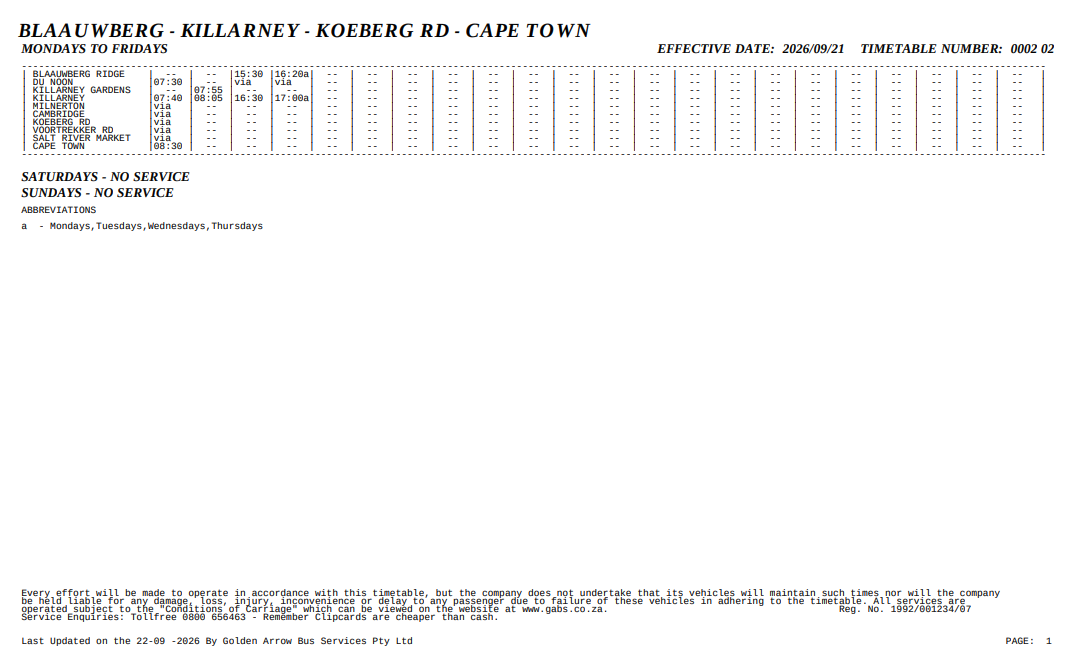. 

I did try an OSM query for the transit stops, but wasn't able to get them (timed out because it was too big - i was looking in the whole municipality). And i do like getting recent data direct from the city through its data portal. For the Golden Arrow bus stops, i could also use smaller areas at a time in my query and resolve duplicates. But OSM only has `bus_stop` as a value, it doesn't differentiate between networks (Golden Arrow and MyCiti). 

So i kept looking.

There is a site called [SpatialDataWarehouse](https://gis.westerncape.gov.za/server2/rest/services/SpatialDataWarehouse) which has a number of transportation datasets, including [Golden Arrow bus stops](https://gis.westerncape.gov.za/server2/rest/services/SpatialDataWarehouse/Transportation/MapServer/6). The description of the data is "Golden Arrow Bus Services Stops as captured by ASPIRE using on-board survey tracking".

The site provides an interface for querying the database. A maximum of 2000 records can be returned in each query, and there is a "Result Offset" field which can be used to get the next page of results (setting the offset to 2000 x n, where n is the number of queries already made).

But it seems that the "on-board survey tracking" does not reliably produce bus stop locations.

The first 200 records:
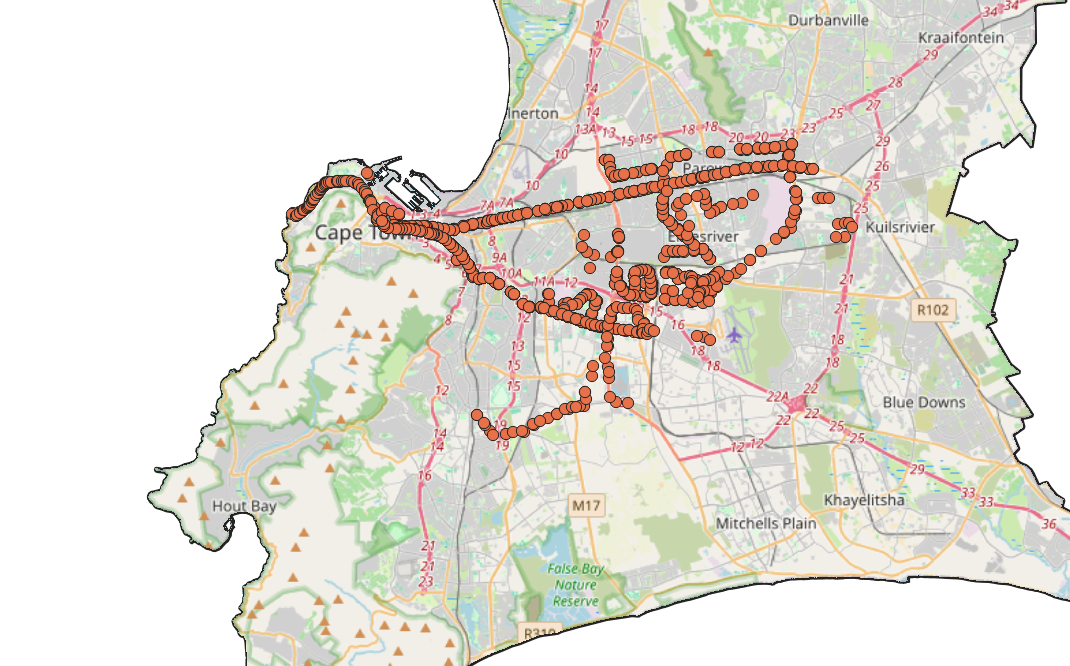

These are too many too close together to all be bus stops. 

For example, the three highlighted points below are within 37 meters of each other, and all on the same route (`SEA POINT to CITY`).
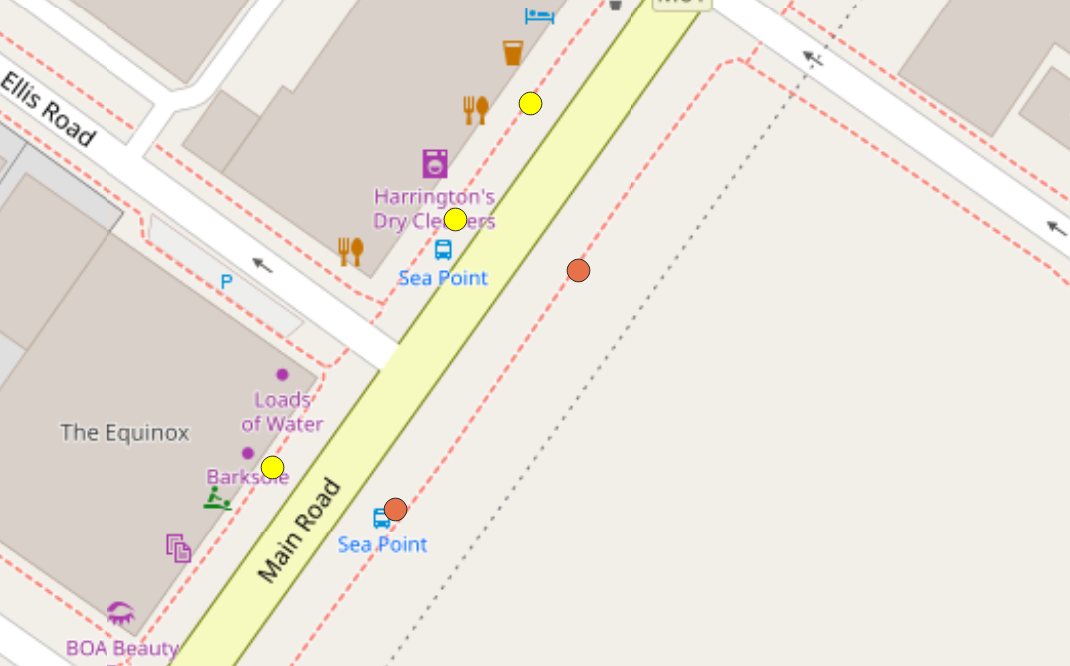

In many areas though, the points are not as dense.
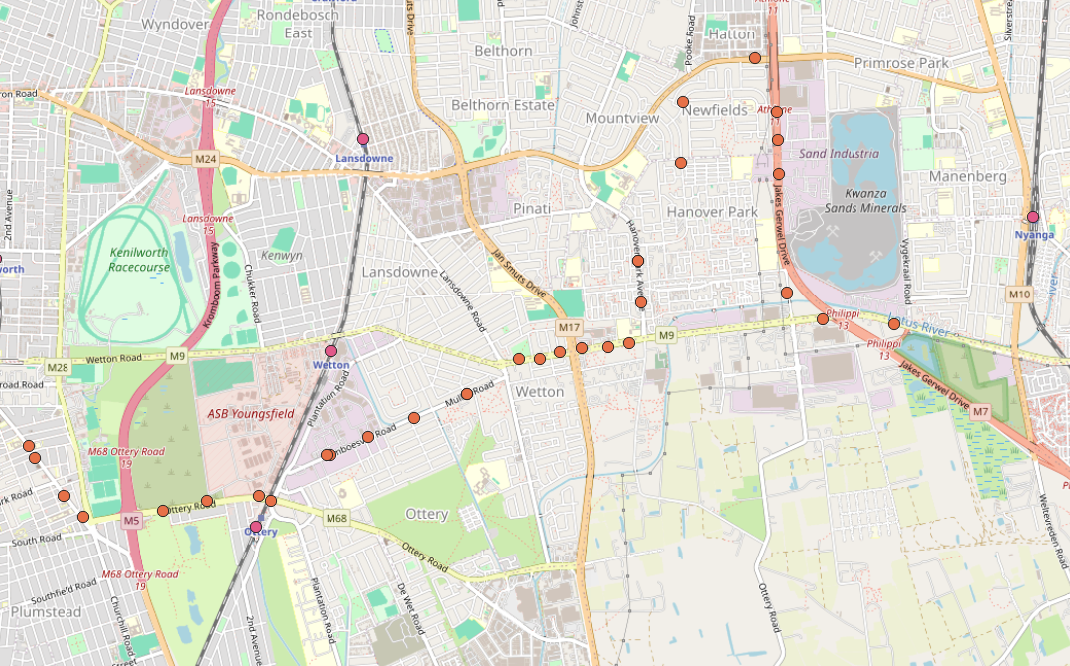

This data may not be completely reliable for bus stop locations, but it does indicate where busses run, and in many areas it looks like the points are reasonably spaced. I think this data will be suitable for the analysis we're doing here. 

The other challenge is that there are many thousands of records and records are duplicated across queries. Even at 80000 records, there is still more data to be returned. Every query returns records that are duplicated in the previous query/queries, and also new records.

What i'm doing is making many queries, loading them all into QGIS, merging the layers and deleting duplicate geometries in batches, and continuing in this way until when i load the queries i'm not seeing any new points appearing or until nothing is returned from the query.

Finally, clipped railway stations, golden arrow bus stops, and taxi routes using the municipal boundary as an overlay